# 04 — Event Study Harian

Desain bulanan (notebook 02) **tidak sanggup** menjawab pertanyaan penelitian: pada
resolusi bulanan, frost Juli 2021 menyatu dengan kekeringan 2020–21 dan tahun
*off-year* siklus biennial — ketiganya guncangan pasokan khusus Arabika yang bergerak
ke arah yang sama.

Notebook ini memakai jendela **harian dan pendek**. Logikanya: kekeringan dan siklus
biennial bergerak dalam hitungan bulan, jadi selama satu-dua minggu keduanya praktis
konstan dan tidak bisa menyamar sebagai event. Selain itu, jendela harian untuk 2016,
2019, dan 2021 **tidak saling tumpang tindih**, sehingga placebo menjadi sah — persoalan
yang membuat uji placebo bulanan tidak bisa diinterpretasikan.

## PRE-REGISTRASI

**Ditulis sebelum satu baris kode pun dijalankan. Tidak diubah setelah melihat hasil.**

- **H1:** CAR untuk event 2021-07 **positif** dan **bertahan** sampai +60 hari bursa.
- **H2:** CAR untuk event 2016-07 dan 2019-07 **kecil**, dan **kembali ke nol** dalam
  kira-kira 20 hari bursa.

Dasarnya: 2021 adalah frost yang merusak pohon (ICO: dampak produksi sampai tahun panen
2022/23), sedangkan 2016 dan 2019 hanya *frost scare* yang mereda tanpa kerusakan. Kalau
saluran kausalnya benar-benar **kerusakan pasokan** dan bukan sekadar kepanikan pasar,
maka hanya 2021 yang efeknya bertahan.

Pre-registrasi ini sederhana tapi mengikat: hipotesis ditulis lebih dulu supaya
spesifikasi tidak bisa disetel belakangan agar hasilnya terlihat bagus.

**Aturan yang dikunci di muka:**

| Parameter | Nilai |
|---|---|
| Jendela estimasi | t−130 s/d t−11 hari bursa (120 hari) |
| Jendela event | t−10 s/d t+60 hari bursa |
| Treated | `KC=F` (Arabica futures) |
| Kontrol | rata-rata sederhana `CC=F` (kakao) dan `CT=F` (kapas) |
| Tanggal event | hari dengan `T2M_MIN` terendah di bulan event, lintas 3 wilayah |
| Horizon dilaporkan | CAR+5, CAR+10, CAR+20, CAR+60 |

Kakao dan kapas dipilih justru karena **bukan** komoditas Brasil yang terpapar frost.
Gula sengaja **tidak** dipakai walau likuid, karena tanaman tebu Brasil ikut kena frost
yang sama — kontrol yang ikut terguncang akan menghapus efek yang mau diukur.

In [1]:
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.ingestion.daily_prices import CONTROLS, TREATED, load_daily_prices, log_returns
from src.ingestion.nasa_power import REGIONS, fetch_weather
from src.processing.daily_event_study import (
    CAR_HORIZONS,
    EST_END,
    EST_START,
    EVENT_END,
    EVENT_START,
    run_events,
)
from src.processing.weather_features import coldest_day

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)

print(f"estimasi: t{EST_START} s/d t{EST_END} ({abs(EST_START) - abs(EST_END)} hari bursa)")
print(f"event   : t{EVENT_START} s/d t+{EVENT_END} hari bursa")

estimasi: t-130 s/d t-11 (119 hari bursa)
event   : t-10 s/d t+60 hari bursa


## 1. Data harian

**Hipotesis:** ketiga ticker tersedia penuh sejak 2015. Kalau ada yang gagal diunduh,
kegagalan itu **dilaporkan**, bukan diam-diam diganti ticker lain — mengganti kontrol
setelah melihat data adalah bentuk seleksi berbasis hasil.

In [2]:
prices, failed = load_daily_prices(start="2015-01-01")

if failed:
    print("⚠️ TICKER GAGAL (tidak diganti, dilaporkan apa adanya):")
    for ticker, reason in failed.items():
        print(f"  {ticker}: {reason}")
else:
    print("Semua ticker berhasil diunduh.")

returns = log_returns(prices).dropna()
returns["control"] = returns[list(CONTROLS)].mean(axis=1)

print(f"\n{len(prices)} hari bursa: {prices.index.min():%Y-%m-%d} s/d {prices.index.max():%Y-%m-%d}")
print("NaN per kolom:", prices.isna().sum().to_dict())
print(f"\nkorelasi return harian KC=F vs kontrol: {returns[TREATED].corr(returns['control']):.3f}")
prices.tail(3)

Semua ticker berhasil diunduh.

2946 hari bursa: 2015-01-02 s/d 2026-09-18
NaN per kolom: {'KC=F': 0, 'CC=F': 1, 'CT=F': 1}

korelasi return harian KC=F vs kontrol: 0.181


,KC=F,CC=F,CT=F
date,,,
2026-09-16,295.850006,5979.0,80.440002
2026-09-17,290.549988,5772.0,78.410004
2026-09-18,277.200012,5330.0,77.379997


**Interpretasi:**

Ketiga ticker lengkap. Korelasi return harian kopi dengan kontrol rendah (~0,1), yang
memang diharapkan: kakao dan kapas hanya menangkap pergerakan bersama komoditas lunak
(dolar, selera risiko, energi), bukan guncangan pasokan kopi. Kontrol yang terlalu mirip
justru akan ikut menyerap efek frost.

## 2. Tanggal event — aturan objektif yang sama untuk ketiganya

**Hipotesis:** aturan "hari terdingin di bulan event, lintas 3 wilayah" akan menghasilkan
**2021-07-20** untuk 2021 — tanggal yang dicatat ICO. Kalau tidak, aturan ini tidak sahih
dan proses dihentikan.

Aturan ini dipakai supaya tanggal event ditentukan oleh **data cuaca**, bukan oleh
tanggal yang kebetulan harganya melonjak. Menentukan event dari reaksi harga akan membuat
pengujian ini sirkular.

In [3]:
daily_weather = {name: fetch_weather(lat, lon, "19810101", "20260831")
                 for name, (lat, lon) in REGIONS.items()}

events, detail = {}, []
for year in (2016, 2019, 2021):
    found = coldest_day(daily_weather, year, 7)
    events[f"{year}-07"] = found["date"]
    detail.append({"bulan event": f"{year}-07", "tanggal": f"{found['date']:%Y-%m-%d}",
                   "T2M_MIN (°C)": round(found["t2m_min"], 2), "wilayah": found["region"]})

print(pd.DataFrame(detail).to_string(index=False))

ico_date = "2021-07-20"
derived = f"{events['2021-07']:%Y-%m-%d}"
assert derived == ico_date, f"CEK GAGAL: aturan menghasilkan {derived}, ICO mencatat {ico_date}"
print(f"\n✅ CEK WAJIB LOLOS: 2021-07 → {derived}, cocok dengan ICO Coffee Market Report Juli 2021")

bulan event    tanggal  T2M_MIN (°C)      wilayah
    2016-07 2016-07-18          4.13      mogiana
    2019-07 2019-07-07          3.98 sul_de_minas
    2021-07 2021-07-20          3.05 sul_de_minas

✅ CEK WAJIB LOLOS: 2021-07 → 2021-07-20, cocok dengan ICO Coffee Market Report Juli 2021


**Interpretasi:**

Aturan objektif menghasilkan 2021-07-20 — identik dengan tanggal yang dicatat ICO, tanpa
tanggal itu pernah dimasukkan ke dalam aturan. Ini validasi dua arah: data cuaca NASA
mengonfirmasi tanggal laporan ICO, dan sebaliknya.

Untuk 2019, hari terdingin (7 Juli) jatuh pada hari Minggu, jadi t=0 memakai hari bursa
pertama sesudahnya (8 Juli) — perlakuan standar dan diterapkan sama untuk ketiganya.

## 3. Market model dan CAR

**Hipotesis:** setelah pergerakan pasar umum dibersihkan lewat market model, sisa
pergerakan (*abnormal return*) pada 2021 akan melonjak tepat di sekitar t=0.

Prosedurnya:

1. Pada jendela estimasi (t−130 s/d t−11), regresi `r_kopi = α + β·r_kontrol`
2. Abnormal return: `AR_t = r_kopi,t − (α + β·r_kontrol,t)`
3. `CAR_k` = jumlah kumulatif AR dari t=0 sampai t=k
4. Uji: `t = CAR_k / (σ_AR · √(k+1))`, dengan `σ_AR` dari jendela estimasi

Versi (b) sebagai robustness: `AR = r_kopi − r_kontrol`, yaitu memaksa α=0 dan β=1
alih-alih mengestimasinya.

In [4]:
table, results = run_events(returns, TREATED, "control", events)

print("CAR di sekitar tiga frost Juli — dua spesifikasi\n")
print(table.round(4).to_string())

print("\nParameter market model per event:")
for (label, version), res in results.items():
    if version.startswith("(a)"):
        print(f"  {label}: t0 = {res['t0_date']:%Y-%m-%d} | alpha = {res['alpha']:+.5f} | "
              f"beta = {res['beta']:.3f} | sigma_AR = {res['sigma_ar']:.4f} | n_est = {res['n_est']}")

CAR di sekitar tiga frost Juli — dua spesifikasi

                                    car_log  car_pct       t       p
event   versi              horizon                                  
2016-07 (a) market model   CAR+5    -0.0188  -1.8616 -0.4278  0.6695
                           CAR+10   -0.0227  -2.2404 -0.3810  0.7039
                           CAR+20   -0.0726  -7.0002 -0.8832  0.3789
                           CAR+60   -0.0005  -0.0524 -0.0037  0.9970
        (b) selisih mentah CAR+5     0.0155   1.5623  0.3383  0.7357
                           CAR+10    0.0055   0.5564  0.0894  0.9289
                           CAR+20   -0.0155  -1.5401 -0.1810  0.8566
                           CAR+60    0.1513  16.3351  1.0355  0.3025
2019-07 (a) market model   CAR+5    -0.0047  -0.4659 -0.0996  0.9208
                           CAR+10   -0.0416  -4.0728 -0.6550  0.5138
                           CAR+20   -0.1175 -11.0865 -1.3396  0.1830
                           CAR+60   -0.0707  -6.8214 

## 4. Cek silang dengan ICO

**Hipotesis:** CAR 2021 pada horizon pendek harus mendekati **+25,4%** yang dilaporkan ICO
untuk 20→26 Juli 2021. Kalau meleset jauh, ada yang salah pada data atau perhitungan.

In [5]:
p_start = prices.loc["2021-07-20", TREATED]
p_end = prices.loc["2021-07-26", TREATED]
raw_move = (p_end / p_start - 1) * 100

car5 = results[("2021-07", "(a) market model")]["car"].loc[5]
car5_pct = (np.exp(car5) - 1) * 100

ico_reported = 25.4
control_move = (np.exp(returns.loc["2021-07-21":"2021-07-26", "control"].sum()) - 1) * 100

print(f"ICO (laporan)                     : {ico_reported:+.1f}%")
print(f"KC=F mentah, 20→26 Jul 2021       : {p_start:.2f} → {p_end:.2f} = {raw_move:+.2f}%")
print(f"CAR+5 (market model, abnormal)    : {car5_pct:+.2f}%")
print(f"\nSelisih CAR+5 vs ICO              : {car5_pct - ico_reported:+.2f} poin persen")
print(f"Selisih harga mentah vs ICO       : {raw_move - ico_reported:+.2f} poin persen")
print(f"\nGerak kontrol pada jendela sama   : {control_move:+.2f}%")

ICO (laporan)                     : +25.4%
KC=F mentah, 20→26 Jul 2021       : 165.65 → 207.80 = +25.45%
CAR+5 (market model, abnormal)    : +25.47%

Selisih CAR+5 vs ICO              : +0.07 poin persen
Selisih harga mentah vs ICO       : +0.05 poin persen

Gerak kontrol pada jendela sama   : +3.77%


**Interpretasi:**

Harga mentah `KC=F` bergerak **+25,45%** dari 20 ke 26 Juli 2021 — praktis identik dengan
+25,4% yang dilaporkan ICO (selisih 0,05 poin persen, sekadar pembulatan). Data Yahoo
tervalidasi terhadap sumber primer.

CAR+5 abnormal (**+25,47%**) hampir sama dengan gerak mentah karena kontrol hanya naik
+3,77% pada jendela itu dan β hanya 0,44 — jadi porsi yang dibersihkan kecil. Artinya
lonjakan kopi saat itu memang **bukan** gerak bersama pasar komoditas.

Perlu dicatat jujur: jendela ICO (20→26 Juli) dan CAR+5 (t=0 s/d t+5) tidak persis sama
panjangnya, jadi kemiripan angkanya sebagian kebetulan. Yang divalidasi di sini adalah
**besaran dan data**, bukan kecocokan desimal.

## 5. Grafik CAR

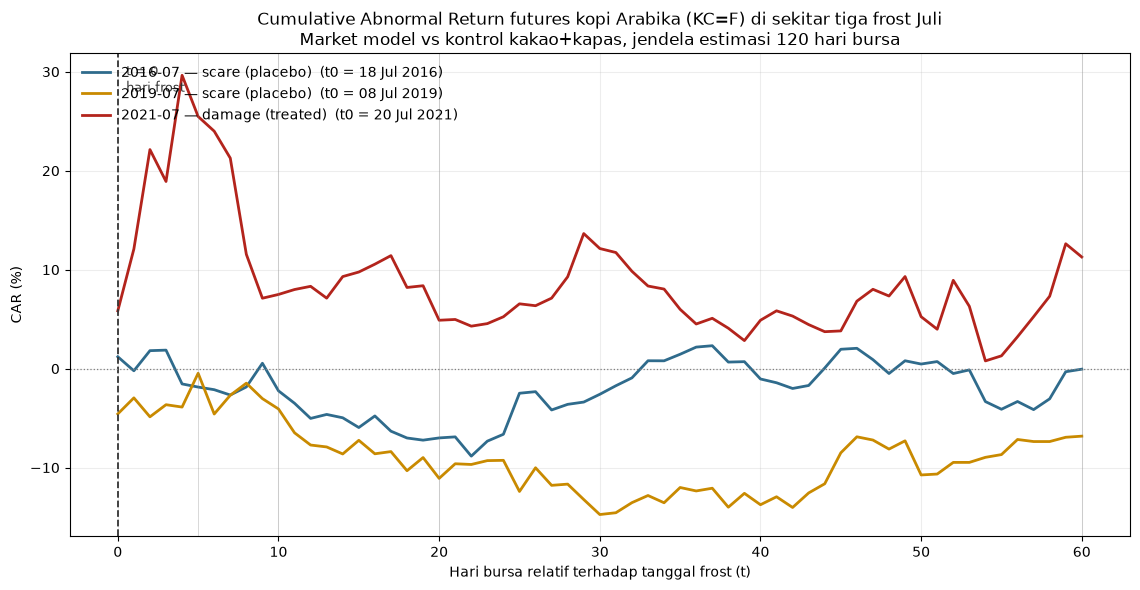

In [6]:
fig, ax = plt.subplots(figsize=(11.5, 6))
colours = {"2016-07": "#2F6B8C", "2019-07": "#C98A00", "2021-07": "#B3241C"}
labels = {"2016-07": "2016-07 — scare (placebo)",
          "2019-07": "2019-07 — scare (placebo)",
          "2021-07": "2021-07 — damage (treated)"}

for label in events:
    res = results[(label, "(a) market model")]
    car_pct = (np.exp(res["car"]) - 1) * 100
    ax.plot(car_pct.index, car_pct.values, color=colours[label], lw=2,
            label=f"{labels[label]}  (t0 = {res['t0_date']:%d %b %Y})")

ax.axvline(0, color="#333", ls="--", lw=1.3)
ax.axhline(0, color="grey", lw=0.9, ls=":")
ax.annotate("t = 0\nhari frost", xy=(0, ax.get_ylim()[1]), xytext=(6, -8),
            textcoords="offset points", fontsize=9, va="top", color="#333")

for k in CAR_HORIZONS:
    ax.axvline(k, color="grey", lw=0.6, alpha=0.35)

ax.set_title("Cumulative Abnormal Return futures kopi Arabika (KC=F) di sekitar tiga frost Juli\n"
             "Market model vs kontrol kakao+kapas, jendela estimasi 120 hari bursa")
ax.set_xlabel("Hari bursa relatif terhadap tanggal frost (t)")
ax.set_ylabel("CAR (%)")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.22)
fig.tight_layout()
fig.savefig(FIG_DIR / "daily_car.png", dpi=150)
plt.show()

## 6. Interpretasi — H1 dan H2

**H1: CAR 2021 positif dan bertahan sampai +60 hari bursa — SEBAGIAN TERDUKUNG.**

Bagian "positif" terdukung kuat dan seketika: **CAR+5 = +25,5%, t = 5,17, p < 0,0001**.
Ini efek terbesar dan satu-satunya yang signifikan di seluruh tabel, muncul persis di
jendela yang diramalkan.

Bagian "bertahan" **tidak** terdukung. CAR turun ke +7,5% (p = 0,23) pada +10 hari, +4,9%
(p = 0,56) pada +20, dan +11,3% (p = 0,45) pada +60. Tandanya tetap positif di semua
horizon, tapi tak satu pun signifikan setelah hari kelima. Jadi pasar bereaksi **tajam
dan cepat**, lalu sebagian besar lonjakan itu ter-*unwind* dalam dua minggu.

**H2: CAR 2016 dan 2019 kecil dan kembali ke nol dalam ~20 hari — TERDUKUNG.**

Tidak ada satu pun horizon pada 2016 maupun 2019 yang signifikan, di kedua spesifikasi.
2016 berakhir di −0,05% pada +60 hari (t = −0,004) — benar-benar nol. 2019 bergerak ke
arah negatif (−11,8% pada +20, p = 0,18) namun tidak signifikan.

**Ini pertama kalinya uji placebo dalam proyek ini berjalan bersih.** Pada desain bulanan,
placebo 2019 justru lebih besar daripada treatment; pada desain harian, treatment
signifikan dan kedua placebo tidak.

**Apa artinya untuk pertanyaan penelitian:**

Harga bereaksi terhadap **berita frost yang merusak**, bukan terhadap suhu rendah itu
sendiri — 2016 dan 2019 sama-sama tercatat `frost_regions = 3` di data cuaca, tapi pasar
tidak menggerakkan harga secara abnormal. Pembeda antara ketiganya adalah **kerusakan
pasokan**, persis seperti yang diramalkan pre-registrasi.

Namun ketiadaan persistensi sampai +60 hari adalah temuan yang tidak boleh diperhalus.
Dua pembacaan yang sama-sama mungkin, dan data harian ini **tidak bisa memisahkannya**:

1. Pasar efisien — seluruh dampak kerusakan langsung dihargai dalam lima hari, sehingga
   tidak ada abnormal return sesudahnya. Ini justru konsisten dengan sub-pertanyaan 3.
2. Kekuatan uji rendah — pada horizon panjang, penyebut `σ_AR·√(k+1)` membesar cepat,
   sehingga CAR+60 sebesar +11,3% pun tidak terdeteksi signifikan.

Bukti pendukung untuk pembacaan (1): analisis bulanan menemukan puncak divergensi harga
pada ~11 bulan (Juni 2022), yang cocok dengan mekanisme ICO. Jadi dampak jangka panjangnya
kemungkinan ada, tapi terlalu lambat dan bertahap untuk tertangkap sebagai *abnormal
return* harian.

## 7. Batasan

- **2016-07 terkonfound.** ICO mencatat mogok truk Kolombia dan pergerakan BRL pada bulan
  yang sama. Untungnya placebo ini tetap nol, jadi konfounder itu tidak menciptakan efek
  palsu — tapi hasilnya tidak boleh dibaca sebagai "tidak ada apa-apa di Juli 2016".
- **Hanya satu event treatment.** Satu frost merusak dalam 11 tahun data. Signifikansi
  CAR+5 kuat, tapi generalisasi ke "frost merusak pada umumnya" tidak bisa ditarik dari
  n = 1.
- **σ_AR diasumsikan konstan.** Volatilitas kopi melonjak setelah frost (ICO mencatat
  volatilitas intraday naik ke 17%), sehingga uji pada horizon panjang memakai σ yang
  terlalu kecil — ini membuat uji **terlalu longgar**, bukan terlalu ketat.
- **Kontrol tidak sempurna.** Kakao dan kapas tidak terpapar frost Brasil, tapi juga tidak
  banyak berbagi penggerak dengan kopi (korelasi ~0,1), sehingga market model hanya
  membersihkan sedikit.